In [9]:
pip install ipympl

Note: you may need to restart the kernel to use updated packages.


In [10]:
%matplotlib widget

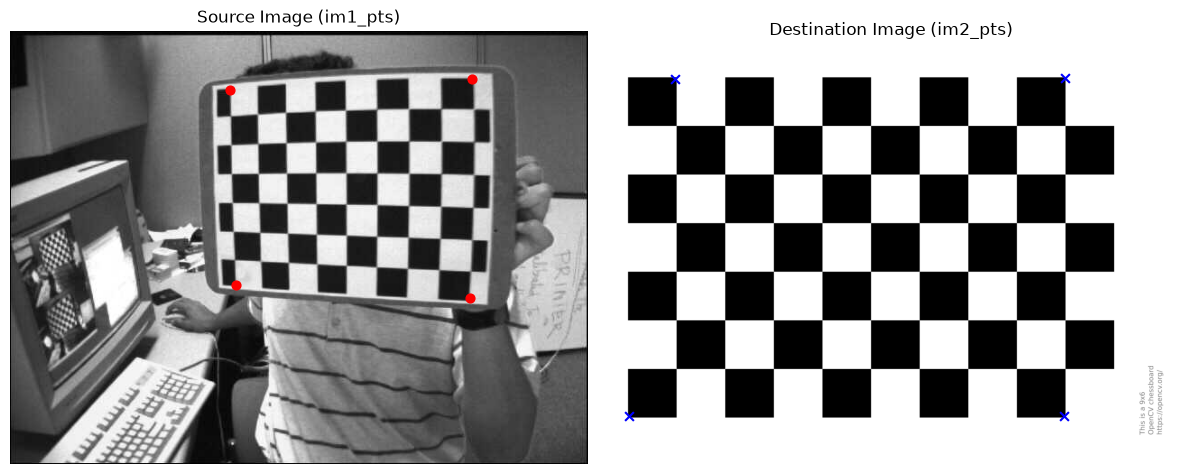

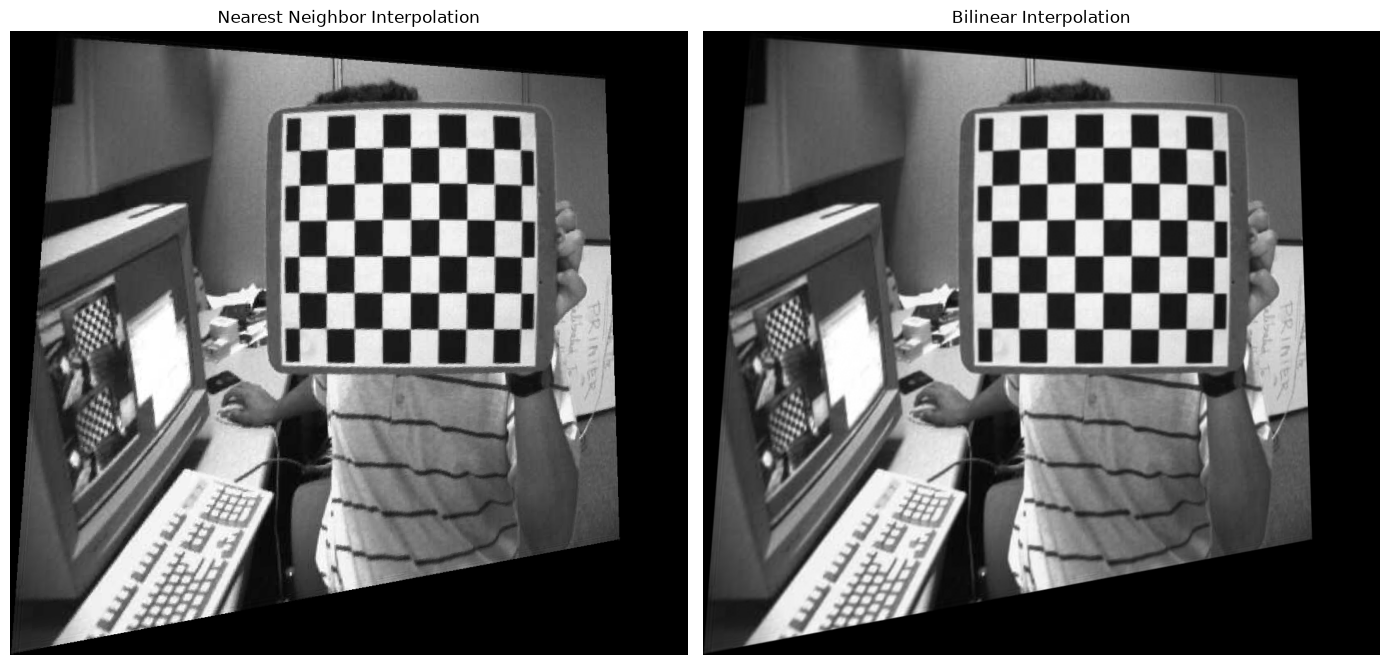

In [39]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images\left01.jpg")
img2 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images\chessboard.png")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

pts1 = np.array([[243, 65], [512, 53], [509, 296], [250, 281]], dtype=np.float64)
pts2 = np.array([[220, 108],[1403, 106],[1402, 1131],[81, 1132]], dtype=np.float64)

def computeH(im1_pts, im2_pts):
    n = im1_pts.shape[0]
    if n < 4:
        raise ValueError("At least 4 point correspondences are required.")
    
    A = []
    for i in range(n):
        x, y = im1_pts[i, 0], im1_pts[i, 1]
        xp, yp = im2_pts[i, 0], im2_pts[i, 1]
        
        row1 = [-x, -y, -1,  0,  0,  0,  x * xp,  y * xp,  xp]
        row2 = [ 0,  0,  0, -x, -y, -1,  x * yp,  y * yp,  yp]
        
        A.append(row1)
        A.append(row2)
        
    A = np.array(A, dtype=np.float64)
    
    _, _, Vt = np.linalg.svd(A)
    h = Vt[-1, :]
    
    H = h.reshape(3, 3)
    if H[2, 2] != 0:
        H = H / H[2, 2]
        
    return H

def visualize_correspondences(img1, img2, im1_pts, im2_pts):
   
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    axes[0].imshow(img1)
    axes[0].scatter(im1_pts[:, 0], im1_pts[:, 1], c='red', s=40, marker='o')
    axes[0].set_title("Source Image (im1_pts)")
    axes[0].axis('off')
    
    axes[1].imshow(img2)
    axes[1].scatter(im2_pts[:, 0], im2_pts[:, 1], c='blue', s=40, marker='x')
    axes[1].set_title("Destination Image (im2_pts)")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

def get_bounding_box(im_shape, H):
    """
    Predicts the bounding box of the warped image with safety clamps 
    to prevent runaway memory errors.
    """
    h, w = im_shape[:2]
    corners = np.array([
        [0, 0, 1],
        [w - 1, 0, 1],
        [w - 1, h - 1, 1],
        [0, h - 1, 1]
    ]).T  # Shape: (3, 4)

    transformed_corners = H @ corners

    z_vals = transformed_corners[2, :]
    z_vals[np.abs(z_vals) < 1e-5] = 1e-5
    transformed_corners /= z_vals
    
    x_coords = transformed_corners[0, :]
    y_coords = transformed_corners[1, :]
    
    all_x = np.append(x_coords, [0, w])
    all_y = np.append(y_coords, [0, h])
    
    x_min = max(int(np.floor(all_x.min())), -2 * w)
    x_max = min(int(np.ceil(all_x.max())), 3 * w)
    y_min = max(int(np.floor(all_y.min())), -2 * h)
    y_max = min(int(np.ceil(all_y.max())), 3 * h)
    
    return x_min, x_max, y_min, y_max


def warpImageNearestNeighbor(im, H):
    """
    Warps image im using homography H with Nearest Neighbor interpolation (inverse warping).
    """
    h, w = im.shape[:2]
    channels = im.shape[2] if len(im.shape) == 3 else 1
    
    x_min, x_max, y_min, y_max = get_bounding_box(im.shape, H)
    out_w = x_max - x_min + 1
    out_h = y_max - y_min + 1
    
    x_indices = np.arange(x_min, x_max + 1)
    y_indices = np.arange(y_min, y_max + 1)
    X_out, Y_out = np.meshgrid(x_indices, y_indices)
    
    num_pixels = out_w * out_h
    ones = np.ones((1, num_pixels))
    coords_out = np.vstack((X_out.flatten(), Y_out.flatten(), ones))

    H_inv = np.linalg.inv(H)
    coords_src = H_inv @ coords_out
    coords_src /= coords_src[2, :]  
    
    X_src = coords_src[0, :].reshape((out_h, out_w))
    Y_src = coords_src[1, :].reshape((out_h, out_w))
    
    X_nn = np.round(X_src).astype(np.int64)
    Y_nn = np.round(Y_src).astype(np.int64)
    
    valid_mask = (X_nn >= 0) & (X_nn < w) & (Y_nn >= 0) & (Y_nn < h)
    
    X_nn_clamped = np.clip(X_nn, 0, w - 1)
    Y_nn_clamped = np.clip(Y_nn, 0, h - 1)
    
    if channels > 1:
        im_warped = np.zeros((out_h, out_w, channels), dtype=im.dtype)
        alpha_mask = np.zeros((out_h, out_w), dtype=np.float64)
        for c in range(channels):
            channel_data = im[:, :, c]
            sampled = channel_data[Y_nn_clamped, X_nn_clamped]
            sampled[~valid_mask] = 0
            im_warped[:, :, c] = sampled
    else:
        im_warped = im[Y_nn_clamped, X_nn_clamped]
        im_warped[~valid_mask] = 0
        im_warped = im_warped.reshape((out_h, out_w))
        
    alpha_mask = valid_mask.astype(np.float64)
    
    return im_warped, alpha_mask


def warpImageBilinear(im, H):
    """
    Warps image im using homography H with Bilinear interpolation (inverse warping).
    """
    h, w = im.shape[:2]
    channels = im.shape[2] if len(im.shape) == 3 else 1
    
    x_min, x_max, y_min, y_max = get_bounding_box(im.shape, H)
    out_w = x_max - x_min + 1
    out_h = y_max - y_min + 1
    
    x_indices = np.arange(x_min, x_max + 1)
    y_indices = np.arange(y_min, y_max + 1)
    X_out, Y_out = np.meshgrid(x_indices, y_indices)
    
    num_pixels = out_w * out_h
    ones = np.ones((1, num_pixels))
    coords_out = np.vstack((X_out.flatten(), Y_out.flatten(), ones))
    
    H_inv = np.linalg.inv(H)
    coords_src = H_inv @ coords_out
    coords_src /= coords_src[2, :]
    
    X_src = coords_src[0, :].reshape((out_h, out_w))
    Y_src = coords_src[1, :].reshape((out_h, out_w))
    
    x0 = np.floor(X_src).astype(np.int64)
    x1 = x0 + 1
    y0 = np.floor(Y_src).astype(np.int64)
    y1 = y0 + 1
    
    wa = (x1 - X_src) * (y1 - Y_src)
    wb = (X_src - x0) * (y1 - Y_src)
    wc = (x1 - X_src) * (Y_src - y0)
    wd = (X_src - x0) * (Y_src - y0)

    valid_mask = (x0 >= 0) & (x1 < w) & (y0 >= 0) & (y1 < h)
 
    x0_c = np.clip(x0, 0, w - 1)
    x1_c = np.clip(x1, 0, w - 1)
    y0_c = np.clip(y0, 0, h - 1)
    y1_c = np.clip(y1, 0, h - 1)
    
    if channels > 1:
        im_warped = np.zeros((out_h, out_w, channels), dtype=np.float64)
        for c in range(channels):
            channel_data = im[:, :, c].astype(np.float64)
            Ia = channel_data[y0_c, x0_c]
            Ib = channel_data[y0_c, x1_c]
            Ic = channel_data[y1_c, x0_c]
            Id = channel_data[y1_c, x1_c]
            
            interpolated = wa * Ia + wb * Ib + wc * Ic + wd * Id
            interpolated[~valid_mask] = 0
            im_warped[:, :, c] = interpolated
        im_warped = np.clip(im_warped, 0, 255).astype(im.dtype)
    else:
        channel_data = im.astype(np.float64)
        Ia = channel_data[y0_c, x0_c]
        Ib = channel_data[y0_c, x1_c]
        Ic = channel_data[y1_c, x0_c]
        Id = channel_data[y1_c, x1_c]
        
        interpolated = wa * Ia + wb * Ib + wc * Ic + wd * Id
        interpolated[~valid_mask] = 0
        im_warped = np.clip(interpolated, 0, 255).astype(im.dtype)
        
    alpha_mask = valid_mask.astype(np.float64)
    
    return im_warped, alpha_mask
    
visualize_correspondences(img1, img2, pts1, pts2)

im_warped, alpha = warpImageBilinear(img1, H_recovered)
im_warped_nn, alpha_nn = warpImageNearestNeighbor(img1, H_recovered)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(im_warped_nn)
axes[0].set_title("Nearest Neighbor Interpolation")
axes[0].axis('off')

axes[1].imshow(im_warped)
axes[1].set_title("Bilinear Interpolation")
axes[1].axis('off')

plt.tight_layout()
plt.show()

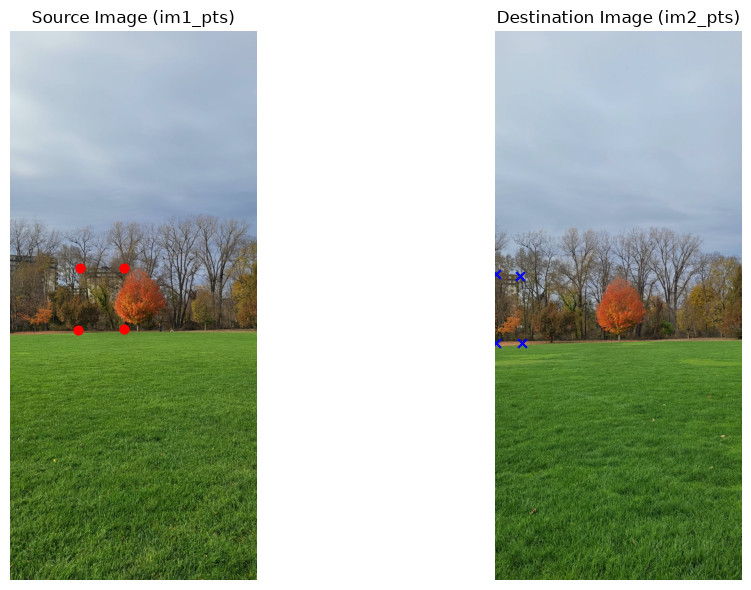

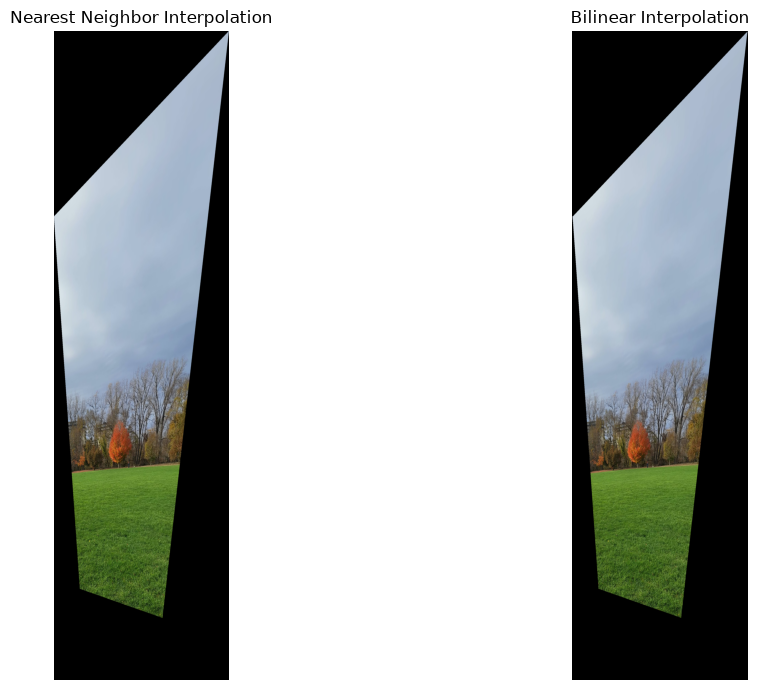

In [48]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images\orange tree 1.jpeg")
img2 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images\orange tree 2.jpeg")

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

pts1 = np.array([[199, 871],[205, 691],[332, 689],[332, 869]], dtype=np.float64)
pts2 = np.array([[3, 908],[1, 708],[73, 712],[77, 908]], dtype=np.float64)

def computeH(im1_pts, im2_pts):
  
    n = im1_pts.shape[0]
    if n < 4:
        raise ValueError("At least 4 point correspondences are required.")
    
    A = []
    for i in range(n):
        x, y = im1_pts[i, 0], im1_pts[i, 1]
        xp, yp = im2_pts[i, 0], im2_pts[i, 1]
   
        row1 = [-x, -y, -1,  0,  0,  0,  x * xp,  y * xp,  xp]
        row2 = [ 0,  0,  0, -x, -y, -1,  x * yp,  y * yp,  yp]
        
        A.append(row1)
        A.append(row2)
        
    A = np.array(A, dtype=np.float64)
  
    _, _, Vt = np.linalg.svd(A)
    h = Vt[-1, :]
 
    H = h.reshape(3, 3)
    if H[2, 2] != 0:
        H = H / H[2, 2]
        
    return H

def visualize_correspondences(img1, img2, im1_pts, im2_pts):
    """
    Visualizes point correspondences side-by-side between two images.
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(img1)
    axes[0].scatter(im1_pts[:, 0], im1_pts[:, 1], c='red', s=40, marker='o')
    axes[0].set_title("Source Image (im1_pts)")
    axes[0].axis('off')

    axes[1].imshow(img2)
    axes[1].scatter(im2_pts[:, 0], im2_pts[:, 1], c='blue', s=40, marker='x')
    axes[1].set_title("Destination Image (im2_pts)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

def get_bounding_box(im_shape, H):
    """
    Predicts the bounding box of the warped image with safety clamps 
    to prevent runaway memory errors.
    """
    h, w = im_shape[:2]
    corners = np.array([
        [0, 0, 1],
        [w - 1, 0, 1],
        [w - 1, h - 1, 1],
        [0, h - 1, 1]
    ]).T  

    transformed_corners = H @ corners

    z_vals = transformed_corners[2, :]
    z_vals[np.abs(z_vals) < 1e-5] = 1e-5
    transformed_corners /= z_vals
    
    x_coords = transformed_corners[0, :]
    y_coords = transformed_corners[1, :]
    
    all_x = np.append(x_coords, [0, w])
    all_y = np.append(y_coords, [0, h])

    x_min = max(int(np.floor(all_x.min())), -2 * w)
    x_max = min(int(np.ceil(all_x.max())), 3 * w)
    y_min = max(int(np.floor(all_y.min())), -2 * h)
    y_max = min(int(np.ceil(all_y.max())), 3 * h)
    
    return x_min, x_max, y_min, y_max


def warpImageNearestNeighbor(im, H):
    """
    Warps image im using homography H with Nearest Neighbor interpolation (inverse warping).
    """
    h, w = im.shape[:2]
    channels = im.shape[2] if len(im.shape) == 3 else 1

    x_min, x_max, y_min, y_max = get_bounding_box(im.shape, H)
    out_w = x_max - x_min + 1
    out_h = y_max - y_min + 1

    x_indices = np.arange(x_min, x_max + 1)
    y_indices = np.arange(y_min, y_max + 1)
    X_out, Y_out = np.meshgrid(x_indices, y_indices)

    num_pixels = out_w * out_h
    ones = np.ones((1, num_pixels))
    coords_out = np.vstack((X_out.flatten(), Y_out.flatten(), ones))

    H_inv = np.linalg.inv(H)
    coords_src = H_inv @ coords_out
    coords_src /= coords_src[2, :] 
    
    X_src = coords_src[0, :].reshape((out_h, out_w))
    Y_src = coords_src[1, :].reshape((out_h, out_w))
    
    X_nn = np.round(X_src).astype(np.int64)
    Y_nn = np.round(Y_src).astype(np.int64)

    valid_mask = (X_nn >= 0) & (X_nn < w) & (Y_nn >= 0) & (Y_nn < h)

    X_nn_clamped = np.clip(X_nn, 0, w - 1)
    Y_nn_clamped = np.clip(Y_nn, 0, h - 1)

    if channels > 1:
        im_warped = np.zeros((out_h, out_w, channels), dtype=im.dtype)
        alpha_mask = np.zeros((out_h, out_w), dtype=np.float64)
        for c in range(channels):
            channel_data = im[:, :, c]
            sampled = channel_data[Y_nn_clamped, X_nn_clamped]
            sampled[~valid_mask] = 0
            im_warped[:, :, c] = sampled
    else:
        im_warped = im[Y_nn_clamped, X_nn_clamped]
        im_warped[~valid_mask] = 0
        im_warped = im_warped.reshape((out_h, out_w))
        
    alpha_mask = valid_mask.astype(np.float64)
    
    return im_warped, alpha_mask


def warpImageBilinear(im, H):
    """
    Warps image im using homography H with Bilinear interpolation (inverse warping).
    """
    h, w = im.shape[:2]
    channels = im.shape[2] if len(im.shape) == 3 else 1

    x_min, x_max, y_min, y_max = get_bounding_box(im.shape, H)
    out_w = x_max - x_min + 1
    out_h = y_max - y_min + 1

    x_indices = np.arange(x_min, x_max + 1)
    y_indices = np.arange(y_min, y_max + 1)
    X_out, Y_out = np.meshgrid(x_indices, y_indices)
    
    num_pixels = out_w * out_h
    ones = np.ones((1, num_pixels))
    coords_out = np.vstack((X_out.flatten(), Y_out.flatten(), ones))

    H_inv = np.linalg.inv(H)
    coords_src = H_inv @ coords_out
    coords_src /= coords_src[2, :]
    
    X_src = coords_src[0, :].reshape((out_h, out_w))
    Y_src = coords_src[1, :].reshape((out_h, out_w))

    x0 = np.floor(X_src).astype(np.int64)
    x1 = x0 + 1
    y0 = np.floor(Y_src).astype(np.int64)
    y1 = y0 + 1

    wa = (x1 - X_src) * (y1 - Y_src)
    wb = (X_src - x0) * (y1 - Y_src)
    wc = (x1 - X_src) * (Y_src - y0)
    wd = (X_src - x0) * (Y_src - y0)
 
    valid_mask = (x0 >= 0) & (x1 < w) & (y0 >= 0) & (y1 < h)

    x0_c = np.clip(x0, 0, w - 1)
    x1_c = np.clip(x1, 0, w - 1)
    y0_c = np.clip(y0, 0, h - 1)
    y1_c = np.clip(y1, 0, h - 1)
    
    if channels > 1:
        im_warped = np.zeros((out_h, out_w, channels), dtype=np.float64)
        for c in range(channels):
            channel_data = im[:, :, c].astype(np.float64)
            Ia = channel_data[y0_c, x0_c]
            Ib = channel_data[y0_c, x1_c]
            Ic = channel_data[y1_c, x0_c]
            Id = channel_data[y1_c, x1_c]
            
            interpolated = wa * Ia + wb * Ib + wc * Ic + wd * Id
            interpolated[~valid_mask] = 0
            im_warped[:, :, c] = interpolated
        im_warped = np.clip(im_warped, 0, 255).astype(im.dtype)
    else:
        channel_data = im.astype(np.float64)
        Ia = channel_data[y0_c, x0_c]
        Ib = channel_data[y0_c, x1_c]
        Ic = channel_data[y1_c, x0_c]
        Id = channel_data[y1_c, x1_c]
        
        interpolated = wa * Ia + wb * Ib + wc * Ic + wd * Id
        interpolated[~valid_mask] = 0
        im_warped = np.clip(interpolated, 0, 255).astype(im.dtype)
        
    alpha_mask = valid_mask.astype(np.float64)
    
    return im_warped, alpha_mask
    
visualize_correspondences(img1, img2, pts1, pts2)

im_warped, alpha = warpImageBilinear(img1, H_recovered)
im_warped_nn, alpha_nn = warpImageNearestNeighbor(img1, H_recovered)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(im_warped_nn)
axes[0].set_title("Nearest Neighbor Interpolation")
axes[0].axis('off')


axes[1].imshow(im_warped)
axes[1].set_title("Bilinear Interpolation")
axes[1].axis('off')

plt.tight_layout()
plt.show()

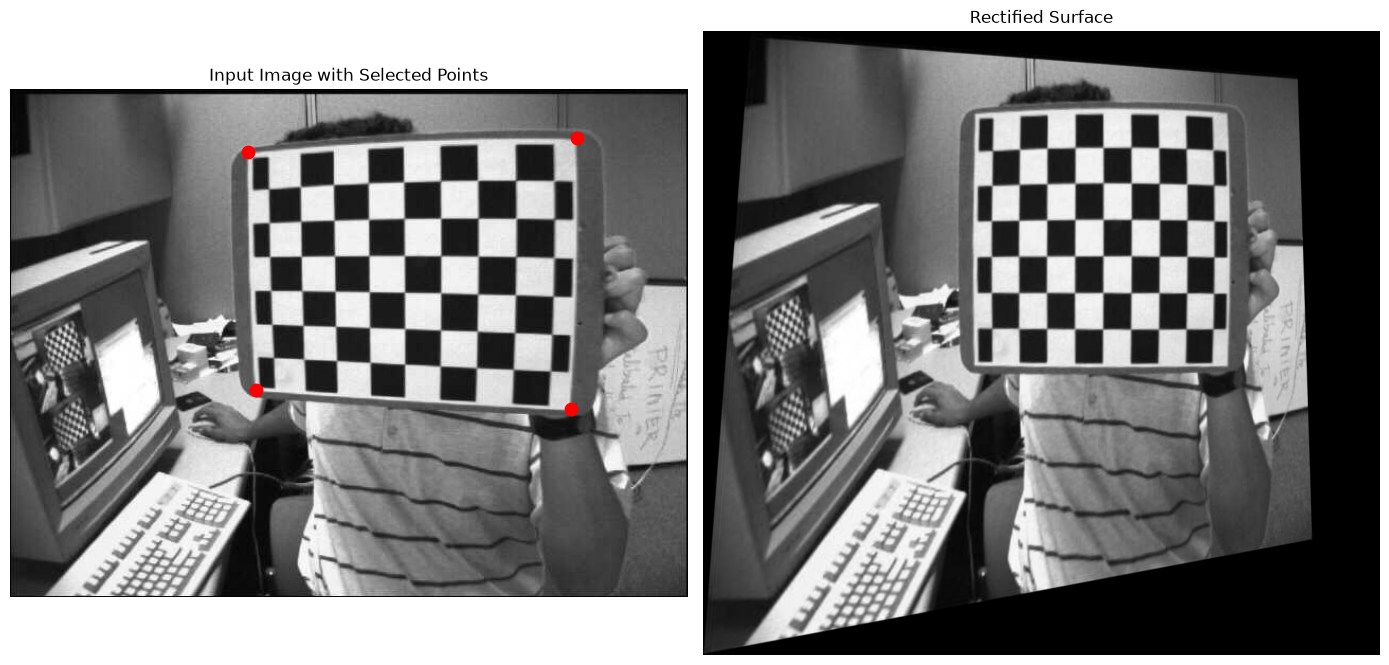

In [49]:
# Rectification
import numpy as np
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread(r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images\left01.jpg")
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

pts1 = np.array([[224, 59],[535, 46],[529, 302],[232, 284]], dtype=np.float64)

width, height = 400, 400
pts2 = np.array([
    [0, 0],         
    [width, 0],       
    [width, height],  
    [0, height]       
], dtype=np.float64)

H_recovered = computeH(pts1, pts2)

im_warped, alpha = warpImageBilinear(img1, H_recovered)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(img1)
axes[0].scatter(pts1[:, 0], pts1[:, 1], color='red', s=80, marker='o')
axes[0].set_title("Input Image with Selected Points")
axes[0].axis('off')

axes[1].imshow(im_warped)
axes[1].set_title("Rectified Surface")
axes[1].axis('off')

plt.tight_layout()
plt.show()

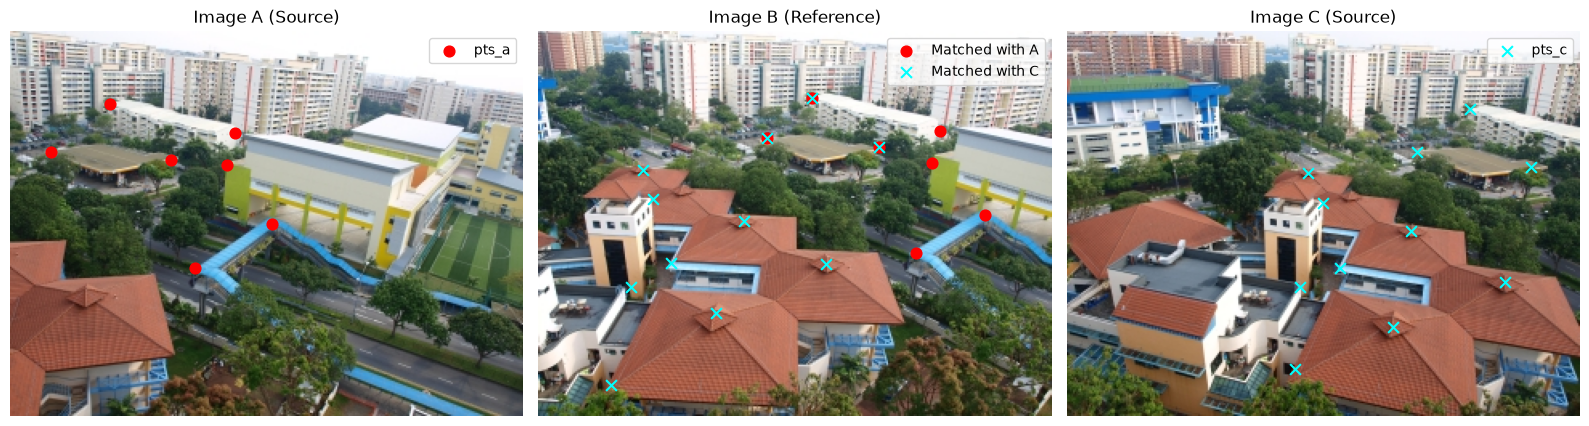

H_a_to_b: reproj err (px) = [0.79 2.82 1.21 1.71 2.57 1.82 1.22]
H_a_to_b: w at corners   = [1.    0.898 0.945 1.047]  (should all be > 0, near 1)
H_c_to_b: reproj err (px) = [1.48 2.96 1.29 4.35 4.92 1.64 5.93 3.62 4.86 4.41 5.26]
H_c_to_b: w at corners   = [1.    1.206 1.219 1.013]  (should all be > 0, near 1)
H_a_to_b:
 [[ 8.72437936e-01  1.72495031e-01  1.07404839e+02]
 [ 3.39159609e-02  9.19128416e-01 -3.32299117e+00]
 [-3.18296544e-04  1.94662651e-04  1.00000000e+00]] 
OpenCV:
 [[ 8.78913526e-01  1.67229934e-01  1.07445746e+02]
 [ 3.67466952e-02  9.16015080e-01 -3.26870800e+00]
 [-2.89112042e-04  1.71108601e-04  1.00000000e+00]]
H_c_to_b:
 [[ 1.23755631e+00 -1.19404192e-01 -1.02072620e+02]
 [-2.39805566e-02  1.17101893e+00 -5.48286731e+00]
 [ 6.47177161e-04  5.43966628e-05  1.00000000e+00]] 
OpenCV:
 [[ 1.25837349e+00 -1.18529483e-01 -1.04522566e+02]
 [-1.91747194e-02  1.18513992e+00 -6.49667456e+00]
 [ 7.13781611e-04  6.50873569e-05  1.00000000e+00]]
Image 0 transformed corners 

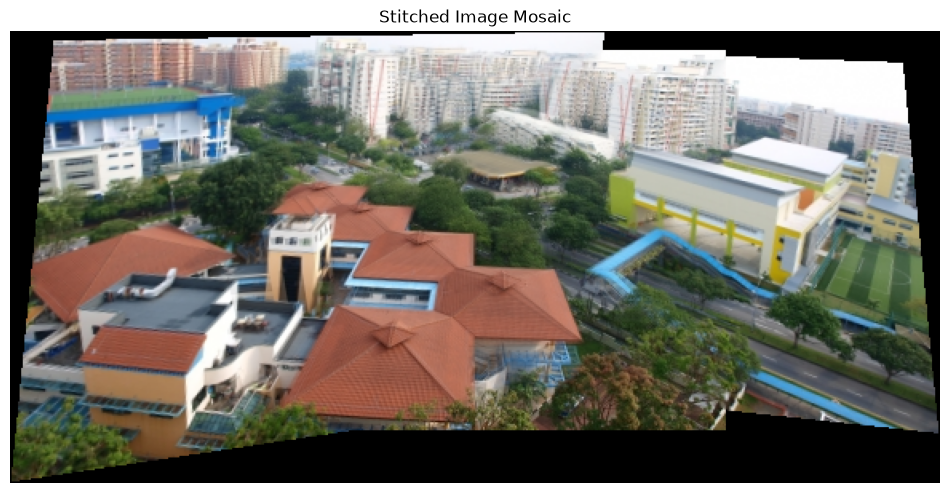

In [50]:
# Blending images into a mosaic (a, b, c -> reference b)
import numpy as np
import cv2
import matplotlib.pyplot as plt

base = r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images"
img_a = cv2.cvtColor(cv2.imread(base + r"\a.jpg"), cv2.COLOR_BGR2RGB)  
img_b = cv2.cvtColor(cv2.imread(base + r"\b.jpg"), cv2.COLOR_BGR2RGB)  
img_c = cv2.cvtColor(cv2.imread(base + r"\c.jpg"), cv2.COLOR_BGR2RGB)  

pts_a = np.array([[25, 75], [100, 80], [62, 45], [140, 63], [135, 83], [163, 120], [115, 147]], dtype=np.float64)
pts_b_for_a = np.array([[142, 66], [212, 72], [170, 41], [250, 62], [245, 82], [278, 114], [235, 138]], dtype=np.float64)

pts_c = np.array([[150, 88], [159, 107], [214, 124], [273, 156], [203, 184], [170, 147],
                  [289, 84], [218, 75], [251, 48], [145, 159], [142, 210]], dtype=np.float64)
pts_b_for_c = np.array([[65, 86], [71, 104], [128, 118], [179, 145], [110, 175], [82, 144],
                        [212, 72], [142, 66], [170, 41], [57, 159], [45, 220]], dtype=np.float64)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(img_a)
axes[0].scatter(pts_a[:, 0], pts_a[:, 1], color='red', s=60, marker='o', label='pts_a')
axes[0].set_title("Image A (Source)")
axes[0].axis('off')
axes[0].legend(loc='upper right')

axes[1].imshow(img_b)
axes[1].scatter(pts_b_for_a[:, 0], pts_b_for_a[:, 1], color='red', s=60, marker='o', label='Matched with A')
axes[1].scatter(pts_b_for_c[:, 0], pts_b_for_c[:, 1], color='cyan', s=60, marker='x', label='Matched with C')
axes[1].set_title("Image B (Reference)")
axes[1].axis('off')
axes[1].legend(loc='upper right')

axes[2].imshow(img_c)
axes[2].scatter(pts_c[:, 0], pts_c[:, 1], color='cyan', s=60, marker='x', label='pts_c')
axes[2].set_title("Image C (Source)")
axes[2].axis('off')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()


def computeH(im1_pts, im2_pts):
    def norm_T(p):
        c = p.mean(axis=0)
        s = np.sqrt(2) / np.mean(np.linalg.norm(p - c, axis=1))
        return np.array([[s, 0, -s * c[0]],
                         [0, s, -s * c[1]],
                         [0, 0, 1]])

    T1, T2 = norm_T(im1_pts), norm_T(im2_pts)
    p1 = (T1 @ np.c_[im1_pts, np.ones(len(im1_pts))].T).T[:, :2]
    p2 = (T2 @ np.c_[im2_pts, np.ones(len(im2_pts))].T).T[:, :2]

    A = []
    for (x, y), (xp, yp) in zip(p1, p2):
        A.append([-x, -y, -1, 0, 0, 0, x * xp, y * xp, xp])
        A.append([0, 0, 0, -x, -y, -1, x * yp, y * yp, yp])
    _, _, Vt = np.linalg.svd(np.array(A, dtype=np.float64))
    Hn = Vt[-1].reshape(3, 3)

    H = np.linalg.inv(T2) @ Hn @ T1
    return H / H[2, 2]


def check_H(name, H, src, dst, img):
    pred = H @ np.c_[src, np.ones(len(src))].T
    pred = pred[:2] / pred[2]
    err = np.linalg.norm(pred - dst.T, axis=0)
    h, w = img.shape[:2]
    corners = np.array([[0, 0, 1], [w - 1, 0, 1], [w - 1, h - 1, 1], [0, h - 1, 1]], dtype=np.float64).T
    w_vals = (H @ corners)[2]
    print(f"{name}: reproj err (px) = {np.round(err, 2)}")
    print(f"{name}: w at corners   = {np.round(w_vals, 3)}  (should all be > 0, near 1)")
    return np.all(w_vals > 0.05)


H_a_to_b = computeH(pts_a, pts_b_for_a)
H_c_to_b = computeH(pts_c, pts_b_for_c)
H_b_to_b = np.eye(3)

ok_a = check_H("H_a_to_b", H_a_to_b, pts_a, pts_b_for_a, img_a)
ok_c = check_H("H_c_to_b", H_c_to_b, pts_c, pts_b_for_c, img_c)

H_cv_a, _ = cv2.findHomography(pts_a, pts_b_for_a, 0)
H_cv_c, _ = cv2.findHomography(pts_c, pts_b_for_c, 0)
print("H_a_to_b:\n", H_a_to_b, "\nOpenCV:\n", H_cv_a / H_cv_a[2, 2])
print("H_c_to_b:\n", H_c_to_b, "\nOpenCV:\n", H_cv_c / H_cv_c[2, 2])

images = [img_a, img_b, img_c]
homographies = [H_a_to_b, H_b_to_b, H_c_to_b]

all_x, all_y = [], []
for i, (img, H) in enumerate(zip(images, homographies)):
    h, w = img.shape[:2]
    corners = np.array([[0, 0, 1], [w - 1, 0, 1], [w - 1, h - 1, 1], [0, h - 1, 1]], dtype=np.float64).T
    t = H @ corners
    t = t / t[2, :]
    print(f"Image {i} transformed corners X: {np.round(t[0], 1)}  Y: {np.round(t[1], 1)}")
    all_x.extend(t[0])
    all_y.extend(t[1])

x_min, x_max = int(np.floor(min(all_x))), int(np.ceil(max(all_x)))
y_min, y_max = int(np.floor(min(all_y))), int(np.ceil(max(all_y)))
out_w = x_max - x_min + 1
out_h = y_max - y_min + 1
print(f"Canvas: {out_w} x {out_h}  (x {x_min}..{x_max}, y {y_min}..{y_max})")

if not (ok_a and ok_c) or out_w > 3000 or out_h > 3000:
    raise SystemExit(
        "Homography looks degenerate (huge canvas or w <= 0 at a corner). "
        "Add more, well-spread correspondences for the offending image pair."
    )

T = np.array([[1, 0, -x_min],
              [0, 1, -y_min],
              [0, 0, 1]], dtype=np.float64)


def warpImageBilinearWithCanvas(im, H_global, out_w, out_h):
    h, w = im.shape[:2]

    mask = np.ones((h, w), dtype=np.uint8) * 255
    mask[0, :] = 0; mask[-1, :] = 0; mask[:, 0] = 0; mask[:, -1] = 0
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    alpha_src = dist / (dist.max() + 1e-5)

    X_out, Y_out = np.meshgrid(np.arange(out_w), np.arange(out_h))
    coords_out = np.vstack((X_out.ravel(), Y_out.ravel(), np.ones(out_w * out_h)))

    H_inv = np.linalg.inv(H_global)
    coords_src = H_inv @ coords_out
    wz = coords_src[2, :]
    wz[np.abs(wz) < 1e-12] = 1e-12
    coords_src = coords_src / wz

    X_src = coords_src[0, :].reshape(out_h, out_w)
    Y_src = coords_src[1, :].reshape(out_h, out_w)

    x0 = np.floor(X_src).astype(np.int64); x1 = x0 + 1
    y0 = np.floor(Y_src).astype(np.int64); y1 = y0 + 1

    wa = (x1 - X_src) * (y1 - Y_src)
    wb = (X_src - x0) * (y1 - Y_src)
    wc = (x1 - X_src) * (Y_src - y0)
    wd = (X_src - x0) * (Y_src - y0)

    valid = (x0 >= 0) & (x1 < w) & (y0 >= 0) & (y1 < h)

    x0c = np.clip(x0, 0, w - 1); x1c = np.clip(x1, 0, w - 1)
    y0c = np.clip(y0, 0, h - 1); y1c = np.clip(y1, 0, h - 1)

    warped = np.zeros((out_h, out_w, 3), dtype=np.float64)
    for c in range(3):
        ch = im[:, :, c].astype(np.float64)
        val = (wa * ch[y0c, x0c] + wb * ch[y0c, x1c] +
               wc * ch[y1c, x0c] + wd * ch[y1c, x1c])
        val[~valid] = 0
        warped[:, :, c] = val

    alpha = (wa * alpha_src[y0c, x0c] + wb * alpha_src[y0c, x1c] +
             wc * alpha_src[y1c, x0c] + wd * alpha_src[y1c, x1c])
    alpha[~valid] = 0
    return warped, alpha


acc_rgb = np.zeros((out_h, out_w, 3), dtype=np.float64)
acc_alpha = np.zeros((out_h, out_w), dtype=np.float64)

for img, H in zip(images, homographies):
    warped, alpha = warpImageBilinearWithCanvas(img, T @ H, out_w, out_h)
    acc_rgb += warped * alpha[:, :, np.newaxis]
    acc_alpha += alpha

acc_alpha[acc_alpha == 0] = 1.0
mosaic = np.clip(acc_rgb / acc_alpha[:, :, np.newaxis], 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 6))
plt.imshow(mosaic)
plt.title("Stitched Image Mosaic")
plt.axis("off")
plt.show()

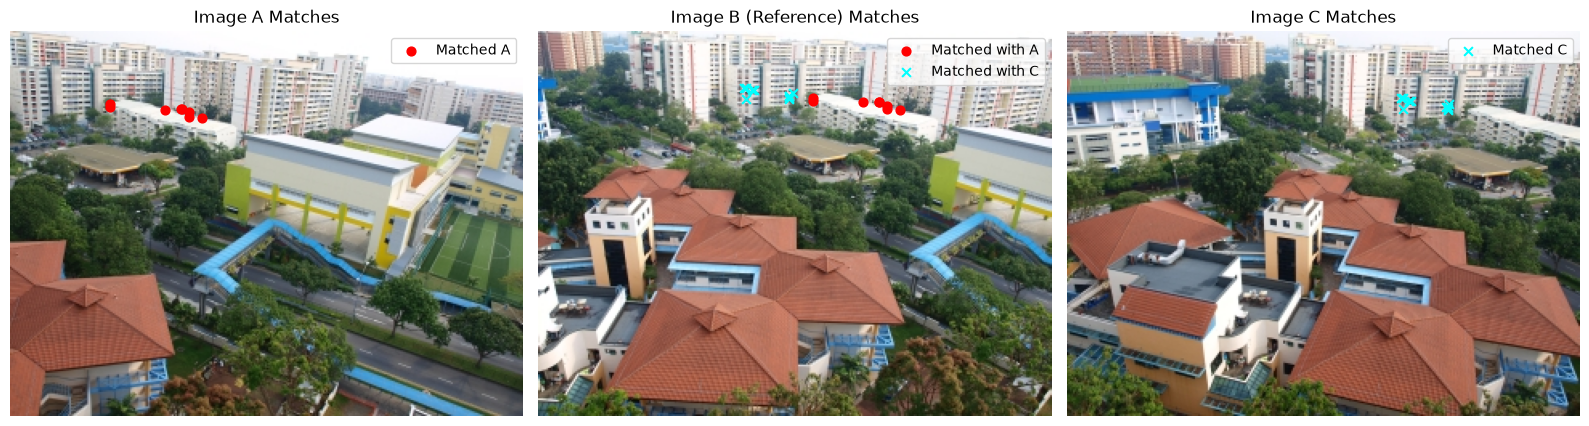

RANSAC finished with 8 inliers out of 8 matches.
RANSAC finished with 10 inliers out of 10 matches.
H_a_to_b: reproj err (px) = [0.6  0.4  0.49 0.31]
H_a_to_b: w at corners   = [1.    0.587 0.579 0.991]  (should all be > 0, near 1)
H_c_to_b: reproj err (px) = [0.44 0.4  0.13 0.17]
H_c_to_b: w at corners   = [1.    0.675 3.271 3.596]  (should all be > 0, near 1)
Image 0 transformed corners X: [118.8 512.3 545.1 134.5]  Y: [  9.  -10.7 280.6 179.2]
Image 1 transformed corners X: [  0. 319. 319.   0.]  Y: [  0.   0. 239. 239.]
Image 2 transformed corners X: [-130.7  332.7  170.2   56. ]  Y: [-11.5 -56.3 115.7 112.6]
Canvas: 678 x 339  (x -131..546, y -57..281)


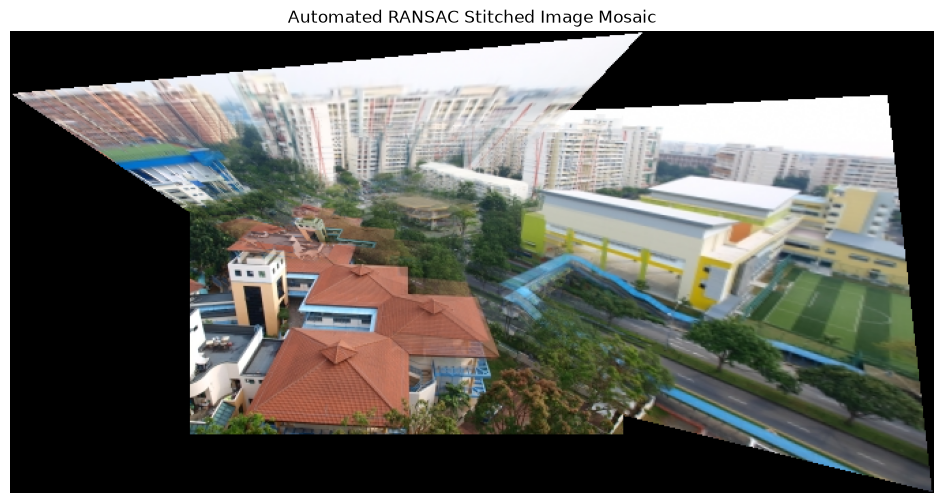

In [51]:
#Automated pipeline with correspondence visualization
import numpy as np
import cv2
import matplotlib.pyplot as plt

base = r"C:\Users\Muhammad Muneeb\Desktop\Documents\Masters\SYDE 671\Assignment 3\images"
img_a = cv2.cvtColor(cv2.imread(base + r"\a.jpg"), cv2.COLOR_BGR2RGB)  
img_b = cv2.cvtColor(cv2.imread(base + r"\b.jpg"), cv2.COLOR_BGR2RGB)  
img_c = cv2.cvtColor(cv2.imread(base + r"\c.jpg"), cv2.COLOR_BGR2RGB)  

def extract_harris_features(img, max_corners=1000, threshold=0.01):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    corners = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)

    dst = cv2.dilate(corners, None)
    ret = dst > threshold * dst.max()
    y_idxs, x_idxs = np.where(ret)
    pts = np.stack((x_idxs, y_idxs), axis=-1)

    if len(pts) > max_corners:
        scores = dst[y_idxs, x_idxs]
        top_indices = np.argsort(scores)[::-1][:max_corners]
        pts = pts[top_indices]
    return pts

def extract_descriptors(img, pts):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    h, w = gray.shape
    descriptors = []
    valid_pts = []
    
    for pt in pts:
        x, y = int(pt[0]), int(pt[1])

        if x - 20 < 0 or x + 20 >= w or y - 20 < 0 or y + 20 >= h:
            continue

        patch_40 = gray[y-20:y+20, x-20:x+20]
        patch_8 = cv2.resize(patch_40, (8, 8), interpolation=cv2.INTER_AREA)

        mean = np.mean(patch_8)
        std = np.std(patch_8)
        if std > 1e-5:
            norm_patch = (patch_8 - mean) / std
        else:
            norm_patch = patch_8 - mean
            
        descriptors.append(norm_patch.flatten())
        valid_pts.append([x, y])
        
    return np.array(valid_pts), np.array(descriptors)

def match_features_lowe(desc1, desc2, pts1, pts2, ratio_thresh=0.75):
    matches = []

    dist_matrix = np.linalg.norm(desc1[:, np.newaxis, :] - desc2[np.newaxis, :, :], axis=2)
    
    for i, row in enumerate(dist_matrix):
        sorted_idxs = np.argsort(row)
        if len(sorted_idxs) < 2:
            continue
        nn1, nn2 = sorted_idxs[0], sorted_idxs[1]
        if row[nn1] < ratio_thresh * row[nn2]:
            matches.append((pts1[i], pts2[nn1]))
            
    if len(matches) == 0:
        return np.empty((0, 2)), np.empty((0, 2))
    
    matches = np.array(matches)
    return matches[:, 0], matches[:, 1]

pts_a_raw = extract_harris_features(img_a)
pts_b_raw = extract_harris_features(img_b)
pts_a_pts, desc_a = extract_descriptors(img_a, pts_a_raw)
pts_b_pts1, desc_b1 = extract_descriptors(img_b, pts_b_raw)
pts_a_matched, pts_b_matched_for_a = match_features_lowe(desc_a, desc_b1, pts_a_pts, pts_b_pts1)

pts_c_raw = extract_harris_features(img_c)
pts_c_pts, desc_c = extract_descriptors(img_c, pts_c_raw)
pts_b_pts2, desc_b2 = extract_descriptors(img_b, pts_b_raw)
pts_c_matched, pts_b_matched_for_c = match_features_lowe(desc_c, desc_b2, pts_c_pts, pts_b_pts2)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(img_a)
axes[0].scatter(pts_a_matched[:, 0], pts_a_matched[:, 1], color='red', s=40, marker='o', label='Matched A')
axes[0].set_title("Image A Matches")
axes[0].axis('off')
axes[0].legend(loc='upper right')

axes[1].imshow(img_b)
axes[1].scatter(pts_b_matched_for_a[:, 0], pts_b_matched_for_a[:, 1], color='red', s=40, marker='o', label='Matched with A')
axes[1].scatter(pts_b_matched_for_c[:, 0], pts_b_matched_for_c[:, 1], color='cyan', s=40, marker='x', label='Matched with C')
axes[1].set_title("Image B (Reference) Matches")
axes[1].axis('off')
axes[1].legend(loc='upper right')

axes[2].imshow(img_c)
axes[2].scatter(pts_c_matched[:, 0], pts_c_matched[:, 1], color='cyan', s=40, marker='x', label='Matched C')
axes[2].set_title("Image C Matches")
axes[2].axis('off')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()


def computeH(im1_pts, im2_pts):
    def norm_T(p):
        c = p.mean(axis=0)
        s = np.sqrt(2) / np.mean(np.linalg.norm(p - c, axis=1))
        return np.array([[s, 0, -s * c[0]],
                         [0, s, -s * c[1]],
                         [0, 0, 1]])

    T1, T2 = norm_T(im1_pts), norm_T(im2_pts)
    p1 = (T1 @ np.c_[im1_pts, np.ones(len(im1_pts))].T).T[:, :2]
    p2 = (T2 @ np.c_[im2_pts, np.ones(len(im2_pts))].T).T[:, :2]

    A = []
    for (x, y), (xp, yp) in zip(p1, p2):
        A.append([-x, -y, -1, 0, 0, 0, x * xp, y * xp, xp])
        A.append([0, 0, 0, -x, -y, -1, x * yp, y * yp, yp])
    _, _, Vt = np.linalg.svd(np.array(A, dtype=np.float64))
    Hn = Vt[-1].reshape(3, 3)

    H = np.linalg.inv(T2) @ Hn @ T1
    return H / H[2, 2]

def ransac_homography(pts1, pts2, num_iterations=1500, threshold=4.0):
    num_pts = len(pts1)
    if num_pts < 4:
        raise ValueError("Not enough matching points found to run RANSAC (need >= 4).")
    
    best_H = None
    max_inliers = -1
    pts1_h = np.hstack([pts1, np.ones((num_pts, 1))])
    
    for _ in range(num_iterations):
        idx = np.random.choice(num_pts, 4, replace=False)
        H_sample = computeH(pts1[idx], pts2[idx])
        
        projected = (H_sample @ pts1_h.T).T
        eps = 1e-8
        projected[:, :2] /= (projected[:, 2:3] + eps)
        
        errors = np.linalg.norm(projected[:, :2] - pts2, axis=1)
        inlier_mask = errors < threshold
        num_inliers = np.sum(inlier_mask)
        
        if num_inliers > max_inliers:
            max_inliers = num_inliers
            best_H = H_sample

    if max_inliers >= 4:
        projected = (best_H @ pts1_h.T).T
        projected[:, :2] /= (projected[:, 2:3] + 1e-8)
        final_mask = np.linalg.norm(projected[:, :2] - pts2, axis=1) < threshold
        if np.sum(final_mask) >= 4:
            best_H = computeH(pts1[final_mask], pts2[final_mask])
            
    print(f"RANSAC finished with {max_inliers} inliers out of {num_pts} matches.")
    return best_H

def check_H(name, H, src, dst, img):
    pred = H @ np.c_[src, np.ones(len(src))].T
    pred = pred[:2] / pred[2]
    err = np.linalg.norm(pred - dst.T, axis=0)
    h, w = img.shape[:2]
    corners = np.array([[0, 0, 1], [w - 1, 0, 1], [w - 1, h - 1, 1], [0, h - 1, 1]], dtype=np.float64).T
    w_vals = (H @ corners)[2]
    print(f"{name}: reproj err (px) = {np.round(err, 2)}")
    print(f"{name}: w at corners   = {np.round(w_vals, 3)}  (should all be > 0, near 1)")
    return np.all(w_vals > 0.05)


H_a_to_b = ransac_homography(pts_a_matched, pts_b_matched_for_a)
H_c_to_b = ransac_homography(pts_c_matched, pts_b_matched_for_c)
H_b_to_b = np.eye(3)

ok_a = check_H("H_a_to_b", H_a_to_b, pts_a_matched[:4], pts_b_matched_for_a[:4], img_a)
ok_c = check_H("H_c_to_b", H_c_to_b, pts_c_matched[:4], pts_b_matched_for_c[:4], img_c)

images = [img_a, img_b, img_c]
homographies = [H_a_to_b, H_b_to_b, H_c_to_b]

all_x, all_y = [], []
for i, (img, H) in enumerate(zip(images, homographies)):
    h, w = img.shape[:2]
    corners = np.array([[0, 0, 1], [w - 1, 0, 1], [w - 1, h - 1, 1], [0, h - 1, 1]], dtype=np.float64).T
    t = H @ corners
    t = t / t[2, :]
    print(f"Image {i} transformed corners X: {np.round(t[0], 1)}  Y: {np.round(t[1], 1)}")
    all_x.extend(t[0])
    all_y.extend(t[1])

x_min, x_max = int(np.floor(min(all_x))), int(np.ceil(max(all_x)))
y_min, y_max = int(np.floor(min(all_y))), int(np.ceil(max(all_y)))
out_w = x_max - x_min + 1
out_h = y_max - y_min + 1
print(f"Canvas: {out_w} x {out_h}  (x {x_min}..{x_max}, y {y_min}..{y_max})")

if not (ok_a and ok_c) or out_w > 4000 or out_h > 4000:
    raise SystemExit(
        "Homography looks degenerate (huge canvas or w <= 0 at a corner). "
        "Check feature matching performance or adjust RANSAC threshold."
    )

T = np.array([[1, 0, -x_min],
              [0, 1, -y_min],
              [0, 0, 1]], dtype=np.float64)


def warpImageBilinearWithCanvas(im, H_global, out_w, out_h):
    h, w = im.shape[:2]

    mask = np.ones((h, w), dtype=np.uint8) * 255
    mask[0, :] = 0; mask[-1, :] = 0; mask[:, 0] = 0; mask[:, -1] = 0
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    alpha_src = dist / (dist.max() + 1e-5)

    X_out, Y_out = np.meshgrid(np.arange(out_w), np.arange(out_h))
    coords_out = np.vstack((X_out.ravel(), Y_out.ravel(), np.ones(out_w * out_h)))

    H_inv = np.linalg.inv(H_global)
    coords_src = H_inv @ coords_out
    wz = coords_src[2, :]
    wz[np.abs(wz) < 1e-12] = 1e-12
    coords_src = coords_src / wz

    X_src = coords_src[0, :].reshape(out_h, out_w)
    Y_src = coords_src[1, :].reshape(out_h, out_w)

    x0 = np.floor(X_src).astype(np.int64); x1 = x0 + 1
    y0 = np.floor(Y_src).astype(np.int64); y1 = y0 + 1

    wa = (x1 - X_src) * (y1 - Y_src)
    wb = (X_src - x0) * (y1 - Y_src)
    wc = (x1 - X_src) * (Y_src - y0)
    wd = (X_src - x0) * (Y_src - y0)

    valid = (x0 >= 0) & (x1 < w) & (y0 >= 0) & (y1 < h)

    x0c = np.clip(x0, 0, w - 1); x1c = np.clip(x1, 0, w - 1)
    y0c = np.clip(y0, 0, h - 1); y1c = np.clip(y1, 0, h - 1)

    warped = np.zeros((out_h, out_w, 3), dtype=np.float64)
    for c in range(3):
        ch = im[:, :, c].astype(np.float64)
        val = (wa * ch[y0c, x0c] + wb * ch[y0c, x1c] +
               wc * ch[y1c, x0c] + wd * ch[y1c, x1c])
        val[~valid] = 0
        warped[:, :, c] = val

    alpha = (wa * alpha_src[y0c, x0c] + wb * alpha_src[y0c, x1c] +
             wc * alpha_src[y1c, x0c] + wd * alpha_src[y1c, x1c])
    alpha[~valid] = 0
    return warped, alpha


acc_rgb = np.zeros((out_h, out_w, 3), dtype=np.float64)
acc_alpha = np.zeros((out_h, out_w), dtype=np.float64)

for img, H in zip(images, homographies):
    warped, alpha = warpImageBilinearWithCanvas(img, T @ H, out_w, out_h)
    acc_rgb += warped * alpha[:, :, np.newaxis]
    acc_alpha += alpha

acc_alpha[acc_alpha == 0] = 1.0
mosaic = np.clip(acc_rgb / acc_alpha[:, :, np.newaxis], 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 6))
plt.imshow(mosaic)
plt.title("Automated RANSAC Stitched Image Mosaic")
plt.axis("off")
plt.show()